# 06 - Boosting: XGBoost

## 1. Objective

Notebook 05 trained the **bagging** ensemble (Random Forest). This notebook trains the other main type of tree ensemble, **boosting**, with XGBoost. It follows exactly the same steps, so the two notebooks can be read side by side:

| Notebook | Ensemble type | Model | How the trees are combined |
|---|---|---|---|
| 05 | Bagging | Random Forest | many independent trees trained in parallel, predictions averaged |
| **06 (this notebook)** | **Boosting** | **XGBoost** | trees trained **one after another**, each one correcting the errors of the trees before it |
| 07 | Comparison | both | bagging vs boosting on the same test rows, with diagnostics |

**Steps in this notebook**
1. **Validation (sections 2-7):** train on target weeks 2007-2022, compare three XGBoost settings on 2023 and choose the best one. The test set is **not used** in these sections.
2. **Final test (section 8):** retrain the chosen setting on all training years (2007-2023) and score it **once** on the test set (2024-2026), next to persistence.
3. **Save (section 9):** the final model and its results, for notebook 07 and the dashboard.

The same 11 features, the same leakage check and the same chronological split as notebooks 04 and 05 are used.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

TRAIN_PATH = Path("../dataset/processed/train.csv")
TEST_PATH = Path("../dataset/processed/test.csv")
MODEL_PATH = Path("../models/06_final_xgboost_model.json")
RESULTS_PATH = Path("../models/06_xgboost_results.json")

# the 11 input features created in notebook 03
FEATURES = [
    "current_week_cases",
    "previous_week_cases",
    "previous_2_weeks_cases",
    "previous_3_weeks_cases",
    "seasonal_cases_previous_52_weeks",
    "moving_average_4_weeks",
    "moving_average_8_weeks",
    "weekly_case_change",
    "seasonal_week_sin",
    "seasonal_week_cos",
    "district_code",
]
TARGET = "cases_next"

VALIDATION_YEAR = 2023
RANDOM_STATE = 42
TREE_MAX_DEPTH = 5  # best Decision Tree setting from notebook 04

# chart colours (the same in notebooks 04-07)
COLORS = {"Persistence": "#898781", "Decision Tree": "#eb6834", "XGBoost": "#1baf7a"}
INK, GRID = "#0b0b0b", "#e4e3df"

## 2. Load the data, remove leaky rows, split by time

The same steps as notebooks 04 and 05, repeated so this notebook runs on its own:
1. Load `train.csv` (target weeks up to 2023 only). The test set is loaded later, in section 8.
2. **Leakage check:** remove rows whose current week was interpolated (`is_imputed`). Their value was calculated from next week's cases, i.e. from the target. Also remove rows whose target was interpolated (`target_imputed`).
3. **Chronological split:** train on target weeks 2007-2022, validate on 2023.

In [2]:
data = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])
assert data["target_date"].max() <= pd.Timestamp("2023-12-31")  # no test weeks
assert data[FEATURES + [TARGET]].notna().all().all()
assert TARGET not in FEATURES and "target_log_next" not in FEATURES

# leakage check: interpolated weeks
leaky_or_estimated = data["is_imputed"] | data["target_imputed"]
data = data[~leaky_or_estimated].reset_index(drop=True)
print("removed interpolated rows:", leaky_or_estimated.sum())

# chronological split
target_year = data["target_date"].dt.year
train = data[target_year < VALIDATION_YEAR]
valid = data[target_year == VALIDATION_YEAR]
assert train["target_date"].max() < valid["target_date"].min()

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]

print("training rows:  ", len(train), "| target weeks", train["target_date"].min().date(), "to", train["target_date"].max().date())
print("validation rows:", len(valid), "| target weeks", valid["target_date"].min().date(), "to", valid["target_date"].max().date())

removed interpolated rows: 52
training rows:   20332 | target weeks 2007-12-29 to 2022-12-31
validation rows: 1352 | target weeks 2023-01-07 to 2023-12-30


## 3. Baselines from notebook 04

- **Persistence:** next week = this week.
- **Decision Tree** with `max_depth = 5` (the best setting in notebook 04). XGBoost adds up many small trees, so this is the "one tree" reference.

**MAE** is the average error in cases, and **RMSE** gives more weight to large misses. Lower is better for both.

In [3]:
def evaluate(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted), "RMSE": root_mean_squared_error(actual, predicted)}

results = []          # validation scores, one row per model
predictions = {}      # validation predictions, used for the charts

predictions["Persistence"] = valid["current_week_cases"].to_numpy()
results.append({"model": "Persistence", "settings": "none", **evaluate(y_valid, predictions["Persistence"])})

decision_tree = DecisionTreeRegressor(max_depth=TREE_MAX_DEPTH, random_state=RANDOM_STATE)
decision_tree.fit(X_train, y_train)
predictions["Decision Tree"] = decision_tree.predict(X_valid)
results.append({"model": "Decision Tree", "settings": f"max_depth={TREE_MAX_DEPTH}",
                **evaluate(y_valid, predictions["Decision Tree"])})

pd.DataFrame(results).round(2)

,model,settings,MAE,RMSE
0,Persistence,none,18.17,41.82
1,Decision Tree,max_depth=5,18.96,43.01


## 4. What is boosting?

**Boosting** builds trees **sequentially**:
1. Start with a simple prediction (the average number of cases).
2. Train a small tree to predict the **errors** (residuals) of the current model.
3. Add this tree to the model, scaled down by the **learning rate** (e.g. 0.1 = take 10% of its correction).
4. Repeat for `n_estimators` rounds.

Each new tree focuses on what the model still gets wrong, so boosting mainly reduces **bias**. The trees are usually shallow (`max_depth` 2-6). Because every tree depends on the trees before it, they **cannot** be trained in parallel like a Random Forest's. With too many rounds or too high a learning rate, boosting can also overfit.

XGBoost ("eXtreme Gradient Boosting", Chen & Guestrin, 2016) is a fast and popular implementation of this idea.

**Settings compared:**

| Setting | `n_estimators` | `max_depth` | `learning_rate` |
|---|---|---|---|
| default | 100 | 6 | 0.3 |
| medium | 200 | 3 | 0.1 |
| slow and shallow | 400 | 2 | 0.05 |

A lower learning rate makes smaller steps, so it needs more rounds.

Unlike a Random Forest (which averages real case counts), boosting adds up corrections and can predict a value **below zero**. Case counts cannot be negative, so XGBoost predictions are clipped at 0 with `np.clip`.

In [4]:
xgb_settings = {
    "default (100 rounds, depth 6, lr 0.3)": {"n_estimators": 100, "max_depth": 6, "learning_rate": 0.3},
    "200 rounds, depth 3, lr 0.1": {"n_estimators": 200, "max_depth": 3, "learning_rate": 0.1},
    "400 rounds, depth 2, lr 0.05": {"n_estimators": 400, "max_depth": 2, "learning_rate": 0.05},
}

xgb_rows = []
xgb_models = {}
for name, params in xgb_settings.items():
    booster = XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1)
    booster.fit(X_train, y_train)
    xgb_models[name] = booster

    train_pred = np.clip(booster.predict(X_train), 0, None)  # no negative case counts
    valid_pred = np.clip(booster.predict(X_valid), 0, None)
    xgb_rows.append({"setting": name, "training MAE": mean_absolute_error(y_train, train_pred),
                     **evaluate(y_valid, valid_pred)})

xgb_results = pd.DataFrame(xgb_rows)
xgb_results.round(2)

,setting,training MAE,MAE,RMSE
0,"default (100 rounds, depth 6, lr 0.3)",5.36,20.40,46.30
1,"200 rounds, depth 3, lr 0.1",8.89,19.21,45.39
2,"400 rounds, depth 2, lr 0.05",9.70,18.10,41.34


**What this shows**

- The **default** XGBoost (deep trees, large learning rate 0.3) overfits the most: training MAE 5.36, but validation MAE **20.40**, worse than the single Decision Tree (18.96).
- Shallower trees with smaller steps generalise better. The **slow and shallow** setting (400 rounds, depth 2, learning rate 0.05) reaches **18.10**.
- As with the Decision Tree and the Random Forest, **simpler, more careful settings work better** on this data.

In [5]:
best_xgb_name = xgb_results.loc[xgb_results["MAE"].idxmin(), "setting"]
best_xgb = xgb_models[best_xgb_name]
XGB_PARAMS = xgb_settings[best_xgb_name]
print("selected XGBoost setting:", best_xgb_name, XGB_PARAMS)

predictions["XGBoost"] = np.clip(best_xgb.predict(X_valid), 0, None)
results.append({"model": "XGBoost", "settings": best_xgb_name,
                **evaluate(y_valid, predictions["XGBoost"])})

selected XGBoost setting: 400 rounds, depth 2, lr 0.05 {'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.05}


**A note on choosing settings.** The setting above was picked using the 2023 validation scores, so these scores are slightly optimistic: we chose the setting that happened to do best on 2023. This is exactly why the test set (2024-2026) is kept separate. It will give the final, unbiased score in section 8.

## 5. Validation results: XGBoost vs the baselines

Validation scores on 2023. The last two columns show the change compared with persistence (negative = better than persistence).

In [6]:
comparison = pd.DataFrame(results).set_index("model")
comparison["MAE vs persistence (%)"] = 100 * (comparison["MAE"] / comparison.loc["Persistence", "MAE"] - 1)
comparison["RMSE vs persistence (%)"] = 100 * (comparison["RMSE"] / comparison.loc["Persistence", "RMSE"] - 1)
comparison.round(2)

,settings,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
model,,,,,
Persistence,none,18.17,41.82,0.00,0.00
Decision Tree,max_depth=5,18.96,43.01,4.37,2.86
XGBoost,"400 rounds, depth 2, lr 0.05",18.10,41.34,-0.39,-1.13


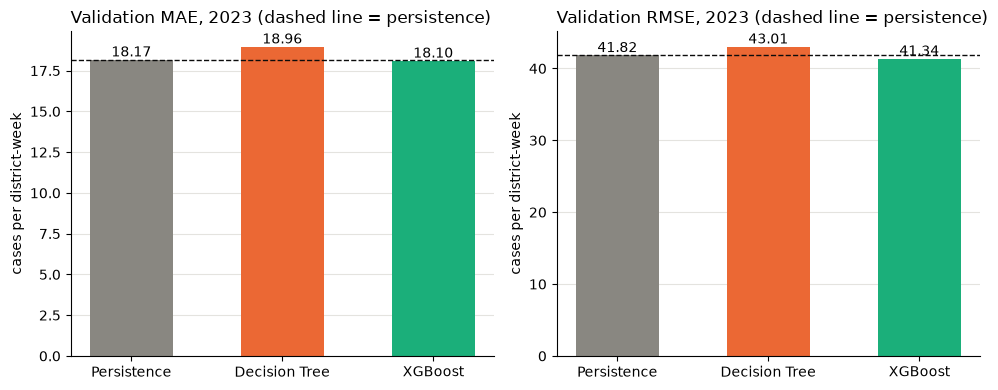

In [7]:
model_names = comparison.index.tolist()
bar_colors = [COLORS[name] for name in model_names]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    values = comparison[metric].to_numpy()
    ax.bar(model_names, values, color=bar_colors, width=0.55)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.axhline(comparison.loc["Persistence", metric], color=INK, linewidth=1, linestyle="--")
    ax.set_title(f"Validation {metric}, 2023 (dashed line = persistence)", loc="left")
    ax.set_ylabel("cases per district-week")
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the validation results show**

- **Boosting clearly beats the single Decision Tree** (MAE 18.10 vs 18.96, RMSE 41.34 vs 43.01). Adding many small, careful corrections works better than one tree.
- **Against persistence it is essentially a tie.** XGBoost has slightly lower MAE (-0.4%) and RMSE (-1.1%). A difference of 0.07 cases per district-week, measured on a single year, is too small to call a real improvement.
- For reference, the Random Forest in notebook 05 reached a validation MAE of 18.14, so on 2023 the two ensembles are practically equal. Notebook 07 compares them on the test years.

## 6. Actual vs predicted: Colombo, 2023

Colombo has the most cases of any district. The chart shows actual weekly cases next to persistence and XGBoost.

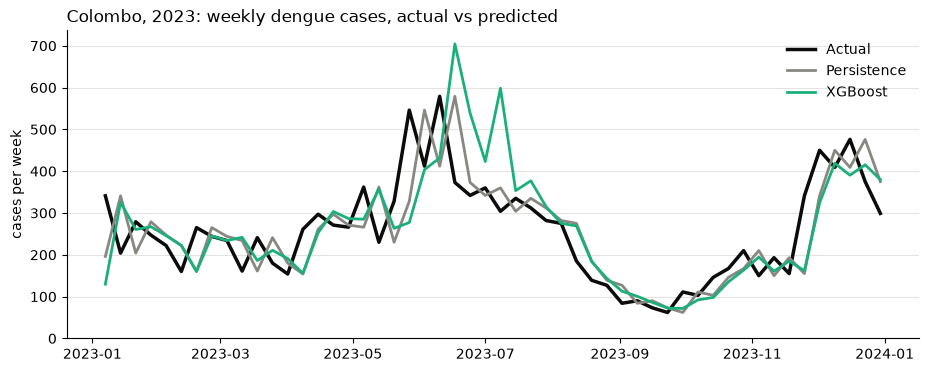

,Persistence,XGBoost
Colombo MAE 2023,65.06,70.75


In [8]:
colombo_rows = (valid["district"] == "Colombo").to_numpy()
colombo_dates = valid.loc[colombo_rows, "target_date"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(colombo_dates, y_valid[colombo_rows], color=INK, linewidth=2.5, label="Actual")
for name in ["Persistence", "XGBoost"]:
    ax.plot(colombo_dates, predictions[name][colombo_rows], color=COLORS[name], linewidth=2, label=name)
ax.set_title("Colombo, 2023: weekly dengue cases, actual vs predicted", loc="left")
ax.set_ylabel("cases per week")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color=GRID)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

pd.DataFrame({name: [mean_absolute_error(y_valid[colombo_rows], predictions[name][colombo_rows])]
              for name in ["Persistence", "XGBoost"]}, index=["Colombo MAE 2023"]).round(2)

Both predictions follow the actual curve about **one week late**: they react to a rise or fall after it has happened.

In Colombo, XGBoost is **worse** than persistence (MAE 70.8 vs 65.1). It **overshoots** after the June peak, predicting about 700 and 600 cases in late June and July when the actual counts had already fallen to around 350-400. So the model with a good overall score is not the best in every district. The same kind of overshoot at an outbreak peak appears again in the test years (section 8 and notebook 07).

## 7. Feature importance

XGBoost reports how much each feature was used to reduce the error (`feature_importances_`). This is a rough guide only: features that are strongly correlated with each other (the lags and moving averages) share the importance between them.

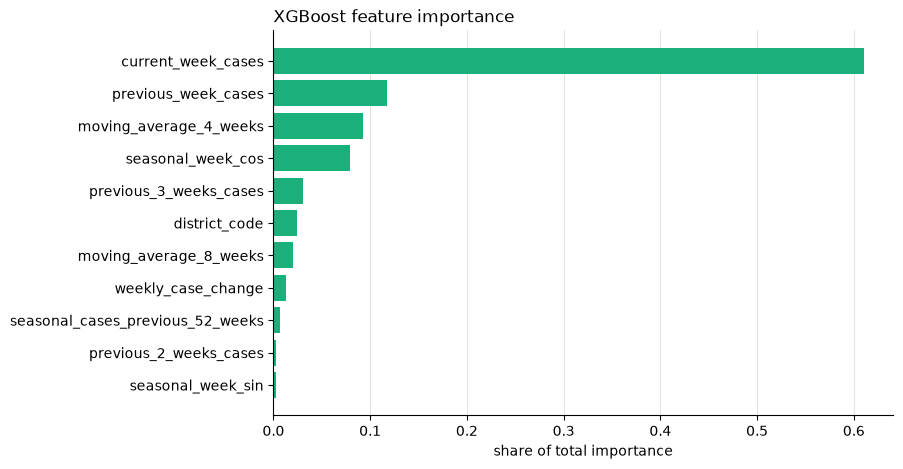

,XGBoost
current_week_cases,0.610
previous_week_cases,0.117
moving_average_4_weeks,0.092
seasonal_week_cos,0.080
previous_3_weeks_cases,0.031
district_code,0.025
moving_average_8_weeks,0.020
weekly_case_change,0.013
seasonal_cases_previous_52_weeks,0.007
previous_2_weeks_cases,0.003


In [9]:
importance = pd.Series(best_xgb.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.to_numpy(), color=COLORS["XGBoost"])
ax.set_xlabel("share of total importance")
ax.set_title("XGBoost feature importance", loc="left")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

importance.sort_values(ascending=False).round(3).to_frame("XGBoost")

- `current_week_cases` is still the most important feature (0.61), but **XGBoost spreads its importance more** than the Random Forest did in notebook 05 (0.87): previous week 0.12, 4-week moving average 0.09 and the seasonal position `seasonal_week_cos` 0.08.
- The 52-week seasonal lag and the longer lags contribute very little.

## 8. Final test (2024-2026)

The setting is now fixed (400 rounds, `max_depth = 2`, `learning_rate = 0.05`), so 2023 is no longer needed for choosing anything.

1. **Retrain** the chosen setting on **all** training years (target weeks 2007-2023), so the model also learns from the most recent data.
2. **Load the test set** (`test.csv`, target weeks 2024-2026) for the first time, with the same leakage check.
3. **Score once** against persistence. Nothing is changed after seeing these scores.

In [10]:
test = pd.read_csv(TEST_PATH, parse_dates=["start_date", "target_date"])

# leakage check: interpolated weeks (same rule as for the training data)
test_leaky = test["is_imputed"] | test["target_imputed"]
test = test[~test_leaky].reset_index(drop=True)
print("removed interpolated test rows:", test_leaky.sum())

# safety checks
assert data["target_date"].max() < test["target_date"].min()                       # all training weeks come first
assert test[FEATURES + [TARGET]].notna().all().all()
assert (test["target_date"] - test["start_date"] == pd.Timedelta(days=7)).all()    # target = the following week

X_final, y_final = data[FEATURES], data[TARGET]   # all training years, 2007-2023
X_test, y_test = test[FEATURES], test[TARGET].to_numpy()

final_xgb = XGBRegressor(**XGB_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)
final_xgb.fit(X_final, y_final)

print("final training rows:", len(data), "| target weeks", data["target_date"].min().date(), "to", data["target_date"].max().date(),
      "| training MAE:", round(mean_absolute_error(y_final, np.clip(final_xgb.predict(X_final), 0, None)), 2))
print("test rows:          ", len(test), "| target weeks", test["target_date"].min().date(), "to", test["target_date"].max().date())

removed interpolated test rows: 106


final training rows: 21684 | target weeks 2007-12-29 to 2023-12-30 | training MAE: 10.31
test rows:           3508 | target weeks 2024-01-06 to 2026-08-29


- **XGBoost:** the model's prediction, clipped at 0 because case counts cannot be negative.
- **Persistence baseline:** next week = this week (`current_week_cases`).

In [11]:
test_predictions = {
    "Persistence": test["current_week_cases"].to_numpy(dtype=float),
    "XGBoost": np.clip(final_xgb.predict(X_test), 0, None),
}

test_results = pd.DataFrame({name: evaluate(y_test, p) for name, p in test_predictions.items()}).T
test_results["MAE vs persistence (%)"] = 100 * (test_results["MAE"] / test_results.loc["Persistence", "MAE"] - 1)
test_results["RMSE vs persistence (%)"] = 100 * (test_results["RMSE"] / test_results.loc["Persistence", "RMSE"] - 1)
test_results.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,12.63,29.93,0.00,0.00
XGBoost,13.22,39.19,4.63,30.94


### Results by test year

2026 only runs until the end of August.

In [12]:
test_year = test["target_date"].dt.year.to_numpy()
year_rows = []
for year in sorted(np.unique(test_year)):
    rows = test_year == year
    row = {"year": int(year), "rows": int(rows.sum()), "mean weekly cases": y_test[rows].mean()}
    for name, p in test_predictions.items():
        row[f"{name} MAE"] = mean_absolute_error(y_test[rows], p[rows])
    row["MAE vs persistence (%)"] = 100 * (row["XGBoost MAE"] / row["Persistence MAE"] - 1)
    year_rows.append(row)

by_year = pd.DataFrame(year_rows).set_index("year")
by_year.round(2)

,rows,mean weekly cases,Persistence MAE,XGBoost MAE,MAE vs persistence (%)
year,,,,,
2024,1352,37.14,10.45,9.47,-9.39
2025,1352,37.57,8.68,8.27,-4.74
2026,804,98.86,22.93,27.82,21.36


**What the test results show**

- **Overall, XGBoost does not beat persistence on the test set.** MAE is 13.22 vs 12.63 (**+4.6%**) and RMSE is 39.19 vs 29.93 (**+30.9%**). On the 2023 validation year the two were tied (XGBoost -0.4% MAE). On new data the small advantage did not hold.
- **It depends on the year.** XGBoost **is better** than persistence in **2024 (-9.4% MAE)** and **2025 (-4.7%)**, both years with moderate dengue activity. It is clearly **worse in 2026 (+21.4%)**, the year of a very large outbreak: average cases per district-week were about 99, compared with about 37 in 2024 and 2025.
- The large errors come from the peaks of the 2026 outbreak, where XGBoost predicted far too many cases (the same overshoot as in Colombo 2023, section 6). Notebook 07 investigates why and compares it with the Random Forest.

## 9. Save the model and the results

- **Model:** `models/06_final_xgboost_model.json`, saved in XGBoost's own JSON format with `save_model`. This format can be loaded again by any XGBoost version, for example in the dashboard. It is loaded back and must give exactly the same test predictions.
- **Results:** `models/06_xgboost_results.json`: the chosen setting, the validation scores and the test scores. Used by notebook 07 and by the dashboard.

In [13]:
MODEL_PATH.parent.mkdir(exist_ok=True)
final_xgb.save_model(MODEL_PATH)

loaded_xgb = XGBRegressor()
loaded_xgb.load_model(MODEL_PATH)
assert np.allclose(np.clip(loaded_xgb.predict(X_test), 0, None), test_predictions["XGBoost"])
print("saved", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1024:.0f} KB)")
print("reloaded model gives identical predictions")


def to_dict(table):
    return {str(k): {c: float(v) for c, v in row.items()} for k, row in table.round(3).to_dict(orient="index").items()}


summary = {
    "created_by": "notebooks analysis/06_boosting_xgboost.ipynb",
    "model": "XGBoost",
    "ensemble_type": "boosting",
    "params": XGB_PARAMS,
    "random_state": RANDOM_STATE,
    "features": FEATURES,
    "target": TARGET,
    "validation_year": VALIDATION_YEAR,
    "removed_rows": "is_imputed or target_imputed (interpolated weeks)",
    "predictions_clipped_at_zero": True,
    "settings_compared": to_dict(xgb_results.set_index("setting")),
    "validation_scores": to_dict(comparison[["MAE", "RMSE"]]),
    "final_train_rows": int(len(data)),
    "test_rows": int(len(test)),
    "test_scores": to_dict(test_results[["MAE", "RMSE"]]),
    "library_versions": {"xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
RESULTS_PATH.write_text(json.dumps(summary, indent=2))
print("saved", RESULTS_PATH)

saved ..\models\06_final_xgboost_model.json (285 KB)
reloaded model gives identical predictions
saved ..\models\06_xgboost_results.json


**Using the saved model:** load it with `XGBRegressor().load_model(...)`, pass the 11 features in the same order (`FEATURES`), and clip the prediction at 0.

## 10. Summary

**Validation (2023)** - trained on 2007-2022

| Model | Type | Settings | Validation MAE | Validation RMSE |
|---|---|---|---|---|
| Persistence | baseline | none | 18.17 | 41.82 |
| Decision Tree | single tree | `max_depth=5` | 18.96 | 43.01 |
| **XGBoost** | **boosting** | 400 rounds, `max_depth=2`, `learning_rate=0.05` | **18.10** | **41.34** |

**Final test (2024-2026)** - trained on 2007-2023, 3,508 district-weeks

| Model | Test MAE | Test RMSE | MAE vs persistence | RMSE vs persistence |
|---|---|---|---|---|
| Persistence | 12.63 | 29.93 | - | - |
| XGBoost | 13.22 | 39.19 | +4.6% | +30.9% |

**Key points**
1. **Boosting also beats a single tree** on the validation year, but only with careful settings: the default XGBoost (depth 6, learning rate 0.3) was worse than one Decision Tree.
2. **Slow and shallow boosting generalises best:** many small steps (learning rate 0.05) with very small trees (depth 2).
3. On the test years XGBoost is **better than persistence in the moderate years 2024-2025**, but its large overestimates at the peak of the 2026 outbreak make it **worse overall**. The small validation advantage did not hold on new data.
4. The leakage check removed interpolated weeks, the setting was chosen on 2023 only, and the test set was used once, so the test scores are fair.

**Saved:** `models/06_final_xgboost_model.json`, `models/06_xgboost_results.json`.

**Next:** notebook 07 compares bagging (Random Forest, notebook 05) and boosting (XGBoost, this notebook) on the same test rows and explains the differences.